# Baselines: aleatoria y FIFO

**He(RL)l Kitchen v2.** Referencias de desempeño contra las que se comparan DQN y PPO (`docs/env_design.md`, sección 4.3). No se entrenan: evaluarlas cuesta segundos.

- **Aleatoria:** acción uniforme. Cota inferior.
- **FIFO ingenua:** trabaja solo sobre la orden más antigua: la prepara, la pone al fuego, prueba cuando se ve casi lista y sirve o descarta según la prueba.

Se evalúan con las **seeds de prueba** (`10000 + i`) en todos los escenarios de la sección 4.6.

**Cómo correrlo**

- **Local:** con el entorno virtual activo, abrir este notebook desde `notebooks/` y ejecutar todo.
- **Google Colab:** abrir el notebook (desde GitHub o subiéndolo), poner en `BRANCH` la rama que se quiere correr y ejecutar todo. La primera celda clona el repo (o lo actualiza si ya estaba) e instala solo lo que Colab no trae.

Las tablas y figuras se guardan en `results/` (o en la carpeta de la variable de entorno `KITCHEN_NB_OUTPUT_DIR`, que usan los tests).

In [1]:
# Arranque: en Colab clona el repo en BRANCH (o lo actualiza); en local no hace nada extra.
BRANCH = "main"   # en Colab: la rama del repo que se quiere correr

import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/PROY-RL").exists():
    subprocess.run(["git", "clone", "--branch", BRANCH,
                    "https://github.com/paulabaal12/PROY-RL.git", "/content/PROY-RL"], check=True)
sys.path.insert(0, "/content/PROY-RL/notebooks" if "google.colab" in sys.modules else ".")

from _setup import setup
ROOT = setup(branch=BRANCH)
print("Raíz del repo:", ROOT)

Raíz del repo: D:\Documentos\GitHub\PROY-RL


In [2]:
%matplotlib inline
import os
from pathlib import Path

import pandas as pd

# Episodios por configuración. Los tests lo bajan con KITCHEN_NB_EPISODES.
EPISODES = int(os.environ.get("KITCHEN_NB_EPISODES", 100))
OUT = Path(os.environ.get("KITCHEN_NB_OUTPUT_DIR", "results"))
FIGURES, TABLES = OUT / "figures", OUT / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
print("Episodios por configuración:", EPISODES)

from agents.baselines import FifoHeuristicPolicy, RandomPolicy
from envs.kitchen_env import KitchenEnv
from experiments import calibrate
from experiments.evaluate import evaluate_scenarios, summarize, to_markdown

WINDOW = 4

Episodios por configuración: 100


## Un episodio en ASCII

Primeros 30 pasos de la FIFO en la cocina `medium`. Cada paso muestra la acción, el nivel **real** de cocción de cada estación (con una barra), lo que **ve** el agente (lectura con ruido), la última prueba, la ventana visible y los eventos.

In [3]:
env = KitchenEnv(window=WINDOW, kitchen="medium", render_mode="ansi")
policy = FifoHeuristicPolicy(WINDOW)
obs, _ = env.reset(seed=0)
total = 0.0
for _ in range(30):
    obs, reward, _, _, _ = env.step(policy(obs))
    total += reward
    print(env.render())
    print(f"Recompensa: {reward:+.2f} | acumulada: {total:+.2f}\n")

=== t =   1/200 ========================================
Acción: prep lugar 0
[Estación 0] vacía
[Estación 1] vacía
[Estación 2] no existe en esta cocina
Ventana (N=4): stirfry#0(prep 1/7, edad 1/29)
Eventos: prepped
Recompensa: +0.00 | acumulada: +0.00

=== t =   2/200 ========================================
Acción: prep lugar 0
[Estación 0] vacía
[Estación 1] vacía
[Estación 2] no existe en esta cocina
Ventana (N=4): stirfry#0(prep 2/7, edad 2/29)
Eventos: prepped
Recompensa: +0.00 | acumulada: +0.00

=== t =   3/200 ========================================
Acción: prep lugar 0
[Estación 0] vacía
[Estación 1] vacía
[Estación 2] no existe en esta cocina
Ventana (N=4): stirfry#0(prep 3/7, edad 3/29)
Eventos: prepped
Recompensa: +0.00 | acumulada: +0.00

=== t =   4/200 ========================================
Acción: prep lugar 0
[Estación 0] vacía
[Estación 1] vacía
[Estación 2] no existe en esta cocina
Ventana (N=4): stirfry#0(prep 4/7, edad 4/29)
Eventos: prepped
Recompensa: +0.00 

## Evaluación por escenario

In [4]:
results = {
    "random": evaluate_scenarios(lambda env: RandomPolicy(env.action_space.n, seed=0),
                                 n_episodes=EPISODES, env_kwargs={"window": WINDOW}),
    "fifo": evaluate_scenarios(lambda env: FifoHeuristicPolicy(WINDOW),
                               n_episodes=EPISODES, env_kwargs={"window": WINDOW}),
}
episodes = pd.concat([df.assign(policy=name) for name, df in results.items()], ignore_index=True)
summary = summarize(results)
episodes.to_csv(TABLES / "baselines_episodes.csv", index=False)
summary.to_csv(TABLES / "baselines_summary.csv", index=False)
(TABLES / "baselines_summary.md").write_text(to_markdown(summary) + "\n", encoding="utf-8")
summary

,policy,scenario,return,on_time_rate,late_rate,expired_rate,bad_serve_rate,tastes_per_order,idle_rate,avoidable_idle_rate,prioritization_rate,prep_ahead_rate
0,random,random,-176.624 ± 48.795,0.002 ± 0.010,0.003 ± 0.011,0.900 ± 0.084,0.958 ± 0.146,1.054 ± 1.015,0.793 ± 0.044,0.057 ± 0.016,0.690 ± 0.087,0.007 ± 0.021
1,random,easy,-103.751 ± 23.315,0.004 ± 0.019,0.003 ± 0.017,0.866 ± 0.106,0.923 ± 0.239,0.854 ± 0.834,0.861 ± 0.040,0.050 ± 0.017,0.567 ± 0.120,0.000 ± 0.000
2,random,medium,-171.923 ± 31.812,0.002 ± 0.010,0.002 ± 0.009,0.899 ± 0.066,0.961 ± 0.141,1.026 ± 0.997,0.789 ± 0.040,0.057 ± 0.017,0.701 ± 0.073,0.013 ± 0.028
3,random,hard,-252.323 ± 28.576,0.003 ± 0.010,0.002 ± 0.007,0.925 ± 0.049,0.938 ± 0.196,1.034 ± 0.979,0.759 ± 0.039,0.058 ± 0.017,0.736 ± 0.059,0.017 ± 0.032
4,random,low_noise,-171.923 ± 31.812,0.002 ± 0.010,0.002 ± 0.009,0.899 ± 0.066,0.961 ± 0.141,1.026 ± 0.997,0.789 ± 0.040,0.057 ± 0.017,0.701 ± 0.073,0.013 ± 0.028
5,random,high_noise,-171.923 ± 31.812,0.002 ± 0.010,0.002 ± 0.009,0.899 ± 0.066,0.961 ± 0.141,1.026 ± 0.997,0.789 ± 0.040,0.057 ± 0.017,0.701 ± 0.073,0.013 ± 0.028
6,random,single_station,-171.183 ± 31.294,0.003 ± 0.013,0.001 ± 0.007,0.912 ± 0.064,0.971 ± 0.094,1.078 ± 1.069,0.796 ± 0.037,0.057 ± 0.017,0.708 ± 0.071,0.147 ± 0.105
7,fifo,random,7.090 ± 78.864,0.441 ± 0.235,0.178 ± 0.080,0.376 ± 0.224,0.008 ± 0.025,2.483 ± 0.598,0.188 ± 0.130,0.034 ± 0.050,0.000 ± 0.000,0.151 ± 0.131
8,fifo,easy,79.173 ± 32.591,0.793 ± 0.167,0.100 ± 0.096,0.097 ± 0.113,0.009 ± 0.032,1.922 ± 0.415,0.464 ± 0.141,0.001 ± 0.003,0.000 ± 0.000,0.016 ± 0.035
9,fifo,medium,12.982 ± 66.155,0.420 ± 0.205,0.195 ± 0.092,0.379 ± 0.193,0.009 ± 0.028,2.490 ± 0.607,0.193 ± 0.096,0.057 ± 0.049,0.000 ± 0.000,0.244 ± 0.091


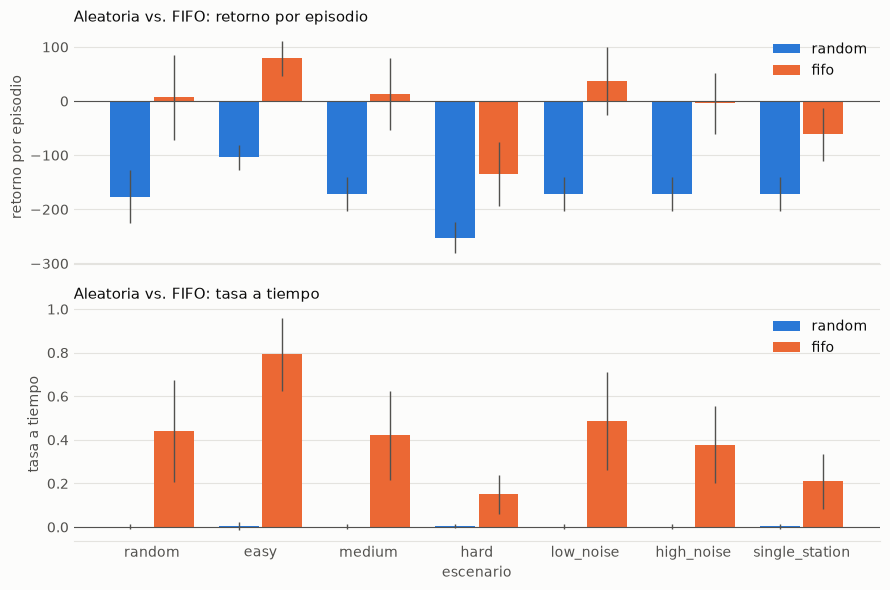

In [5]:
fig = calibrate.plot_difficulty(episodes, out_dir=None)
fig.savefig(FIGURES / "baselines_by_scenario.png", dpi=150, facecolor=fig.get_facecolor())

## Conclusiones

Resultados con 100 episodios por escenario, en las seeds de prueba, con ventana N = 4. Los valores son media ± desviación estándar entre episodios.

| Escenario | Aleatoria (retorno) | FIFO (retorno) | FIFO a tiempo | FIFO expiradas |
|---|---|---|---|---|
| Randomizado | −176.6 ± 48.8 | 7.1 ± 78.9 | 44.1 % | 37.6 % |
| Fácil | −103.8 ± 23.3 | 79.2 ± 32.6 | 79.3 % | 9.7 % |
| Medio | −171.9 ± 31.8 | 13.0 ± 66.2 | 42.0 % | 37.9 % |
| Difícil | −252.3 ± 28.6 | −134.4 ± 58.6 | 15.0 % | 70.4 % |
| Ruido bajo | −171.9 ± 31.8 | 37.6 ± 62.8 | 48.6 % | 30.9 % |
| Ruido alto | −171.9 ± 31.8 | −4.2 ± 56.5 | 37.8 % | 43.6 % |
| Una estación | −171.2 ± 31.3 | −61.5 ± 49.6 | 20.9 % | 61.4 % |

- **La aleatoria funciona como cota inferior.** Casi nunca entrega a tiempo (entre 0.2 % y 0.4 %). Da exactamente lo mismo con ruido bajo, medio y alto porque no mira la observación.
- **La FIFO supera claramente a la aleatoria en todos los escenarios**, así que el ambiente no se resuelve solo.
- **La FIFO pierde por tiempo, no por calidad.** Sirve mal apenas entre 0.8 % y 1.3 % de sus platos, pero deja expirar entre 9.7 % y 70.4 % de las órdenes. Ahí está el margen para que un agente mejore: decidir qué orden atender y mantenerse ocupado.
- **El ruido le cuesta caro.** De ruido bajo a ruido alto el retorno baja de 37.6 a −4.2, y la FIFO sube de 1.93 a 3.12 pruebas por orden para compensar.
- **La variabilidad es alta en la cocina randomizada** (desviación de 78.9) porque cada episodio es una cocina distinta. Por eso DQN y PPO se comparan con las mismas seeds y con intervalos de confianza entre seeds de entrenamiento.